# Consistent adaptive terminal pruning on actual mesh vertices

All timings are from one fresh frozen study. Ratios above one favor the candidate; incomplete navigation is never a time win. Intermediate mesh vertices carry g, learned h, OPEN entries and policies.

In [1]:
from pathlib import Path
import json, hashlib
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
ad=root/'cpp/mesh_lift/results/full/analysis'
a=json.loads((ad/'analysis.json').read_text())
assert a['status']=='passed'
for name,h in a['tables_sha256'].items():
    assert hashlib.sha256((ad/name).read_bytes()).hexdigest()==h
{k:a[k] for k in ['scenarios','timed_runs','memory_runs','allocation_matched_rows','exact_cost_disagreements','capped_calls','terminal_prunes','count_only_runs']}

{'scenarios': 232,
 'timed_runs': 9720,
 'memory_runs': 3240,
 'allocation_matched_rows': 63104,
 'exact_cost_disagreements': 0,
 'capped_calls': 207,
 'terminal_prunes': 87286228,
 'count_only_runs': 2316}

,cohort,control,panel,method,baseline,configurations,pairs,full_speedup,initial_speedup,repair_speedup,memory_multiplier,wins10
1,navigation_dynamic,car16,navigation,cascade_lift,best_control,36,23,0.243474,0.348845,0.065252,4.750231,0
2,navigation_dynamic,car16,navigation,cascade_lift,best_mesh,36,23,0.397383,0.554346,0.096822,1.357605,0
3,navigation_dynamic,car16,navigation,cascade_lift,cascade_cold,36,23,0.403939,0.544227,0.099553,1.392112,2
4,navigation_dynamic,car16,navigation,cascade_lift,cascade_mesh,36,17,1.086728,1.109153,1.033664,0.966442,6
8,navigation_dynamic,car16,navigation,cascade_lift,lift_cold,36,23,0.438586,0.574508,0.101582,1.392112,2
...,...,...,...,...,...,...,...,...,...,...,...,...
133,replay,grid8,main,lift_mesh,cascade_cold,96,96,0.821122,0.548417,0.831188,1.028688,34
135,replay,grid8,main,lift_mesh,cascade_mesh,96,96,1.108588,1.258308,0.986031,0.951466,58
139,replay,grid8,main,lift_mesh,lift_cold,96,96,0.826114,0.550931,0.842078,1.028412,36
140,replay,grid8,main,lift_mesh,lift_noprune,96,96,1.010555,1.130314,0.914924,0.946856,17


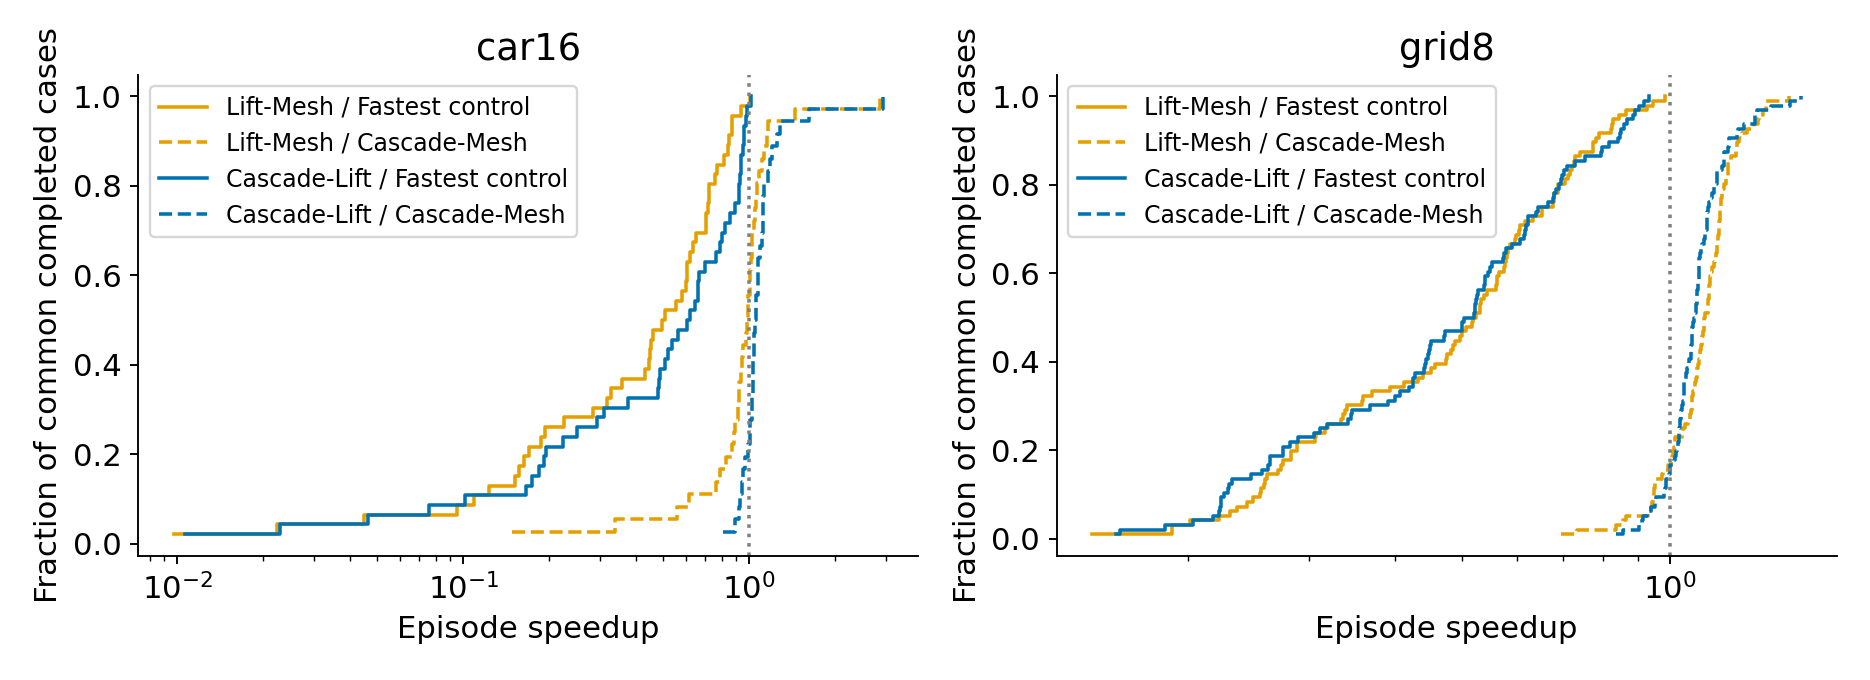

In [2]:
s=pd.read_csv(ad/'summary.csv')
display(s[s.baseline.isin(['best_control','best_mesh','cascade_mesh','mesha_reuse','lift_noprune','lift_cold','cascade_cold'])])
display(Image(filename=str(root/'docs/mesh_lift/figures/profile.png')))

,cohort,control,panel,map,method,baseline,configurations,pairs,full_speedup,initial_speedup,repair_speedup,memory_multiplier,wins10
1,navigation_dynamic,car16,navigation,AR0700,cascade_lift,best_control,6,2,0.537079,0.543466,0.994984,1.707605,0
13,navigation_dynamic,car16,navigation,AR0700,lift_mesh,best_control,6,2,0.187726,0.504055,0.081651,1.707605,0
25,navigation_dynamic,car16,navigation,Berlin,cascade_lift,best_control,6,2,0.433267,0.444515,0.405609,4.901333,0
37,navigation_dynamic,car16,navigation,Berlin,lift_mesh,best_control,6,2,0.282365,0.434065,0.084786,4.901333,0
49,navigation_dynamic,car16,navigation,MA_maze96,cascade_lift,best_control,6,6,0.030822,0.103918,0.003206,27.096600,0
61,navigation_dynamic,car16,navigation,MA_maze96,lift_mesh,best_control,6,6,0.027508,0.097777,0.002813,27.043975,0
73,navigation_dynamic,car16,navigation,MA_random96,cascade_lift,best_control,6,5,0.686977,0.658842,0.785385,1.666009,0
85,navigation_dynamic,car16,navigation,MA_random96,lift_mesh,best_control,6,5,0.304653,0.636502,0.135267,1.664340,0
97,navigation_dynamic,car16,navigation,MA_room96,cascade_lift,best_control,6,4,0.223926,0.285189,0.104218,10.072787,0
109,navigation_dynamic,car16,navigation,MA_room96,lift_mesh,best_control,6,4,0.192518,0.286987,0.064097,10.061041,0


,cohort,control,map,radius,k,cr,method,baseline,configurations,pairs,full_speedup,initial_speedup,repair_speedup,memory_multiplier,wins10
4,navigation_dynamic,car16,AR0700,0,2,5,cascade_lift,cascade_mesh,2,0,NaN,NaN,NaN,NaN,0
17,navigation_dynamic,car16,AR0700,0,2,5,lift_mesh,cascade_mesh,2,0,NaN,NaN,NaN,NaN,0
28,navigation_dynamic,car16,AR0700,0,8,10,cascade_lift,cascade_mesh,2,1,1.005084,1.029132,0.994984,0.546191,0
41,navigation_dynamic,car16,AR0700,0,8,10,lift_mesh,cascade_mesh,2,1,0.120321,0.867461,0.081651,0.546191,0
52,navigation_dynamic,car16,AR0700,0,32,20,cascade_lift,cascade_mesh,2,1,1.072406,1.072406,NaN,1.000006,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
953,navigation_unknown,car16,arena,16,0,0,lift_mesh,cascade_mesh,2,2,0.979370,1.058393,0.907325,1.000395,1
964,navigation_unknown,car16,arena,32,0,0,cascade_lift,cascade_mesh,2,2,1.014070,1.175572,0.828695,1.000435,1
977,navigation_unknown,car16,arena,32,0,0,lift_mesh,cascade_mesh,2,2,1.105873,1.120534,0.956543,1.000435,1
988,navigation_unknown,car16,arena,64,0,0,cascade_lift,cascade_mesh,2,2,1.003225,1.003225,NaN,1.000425,0


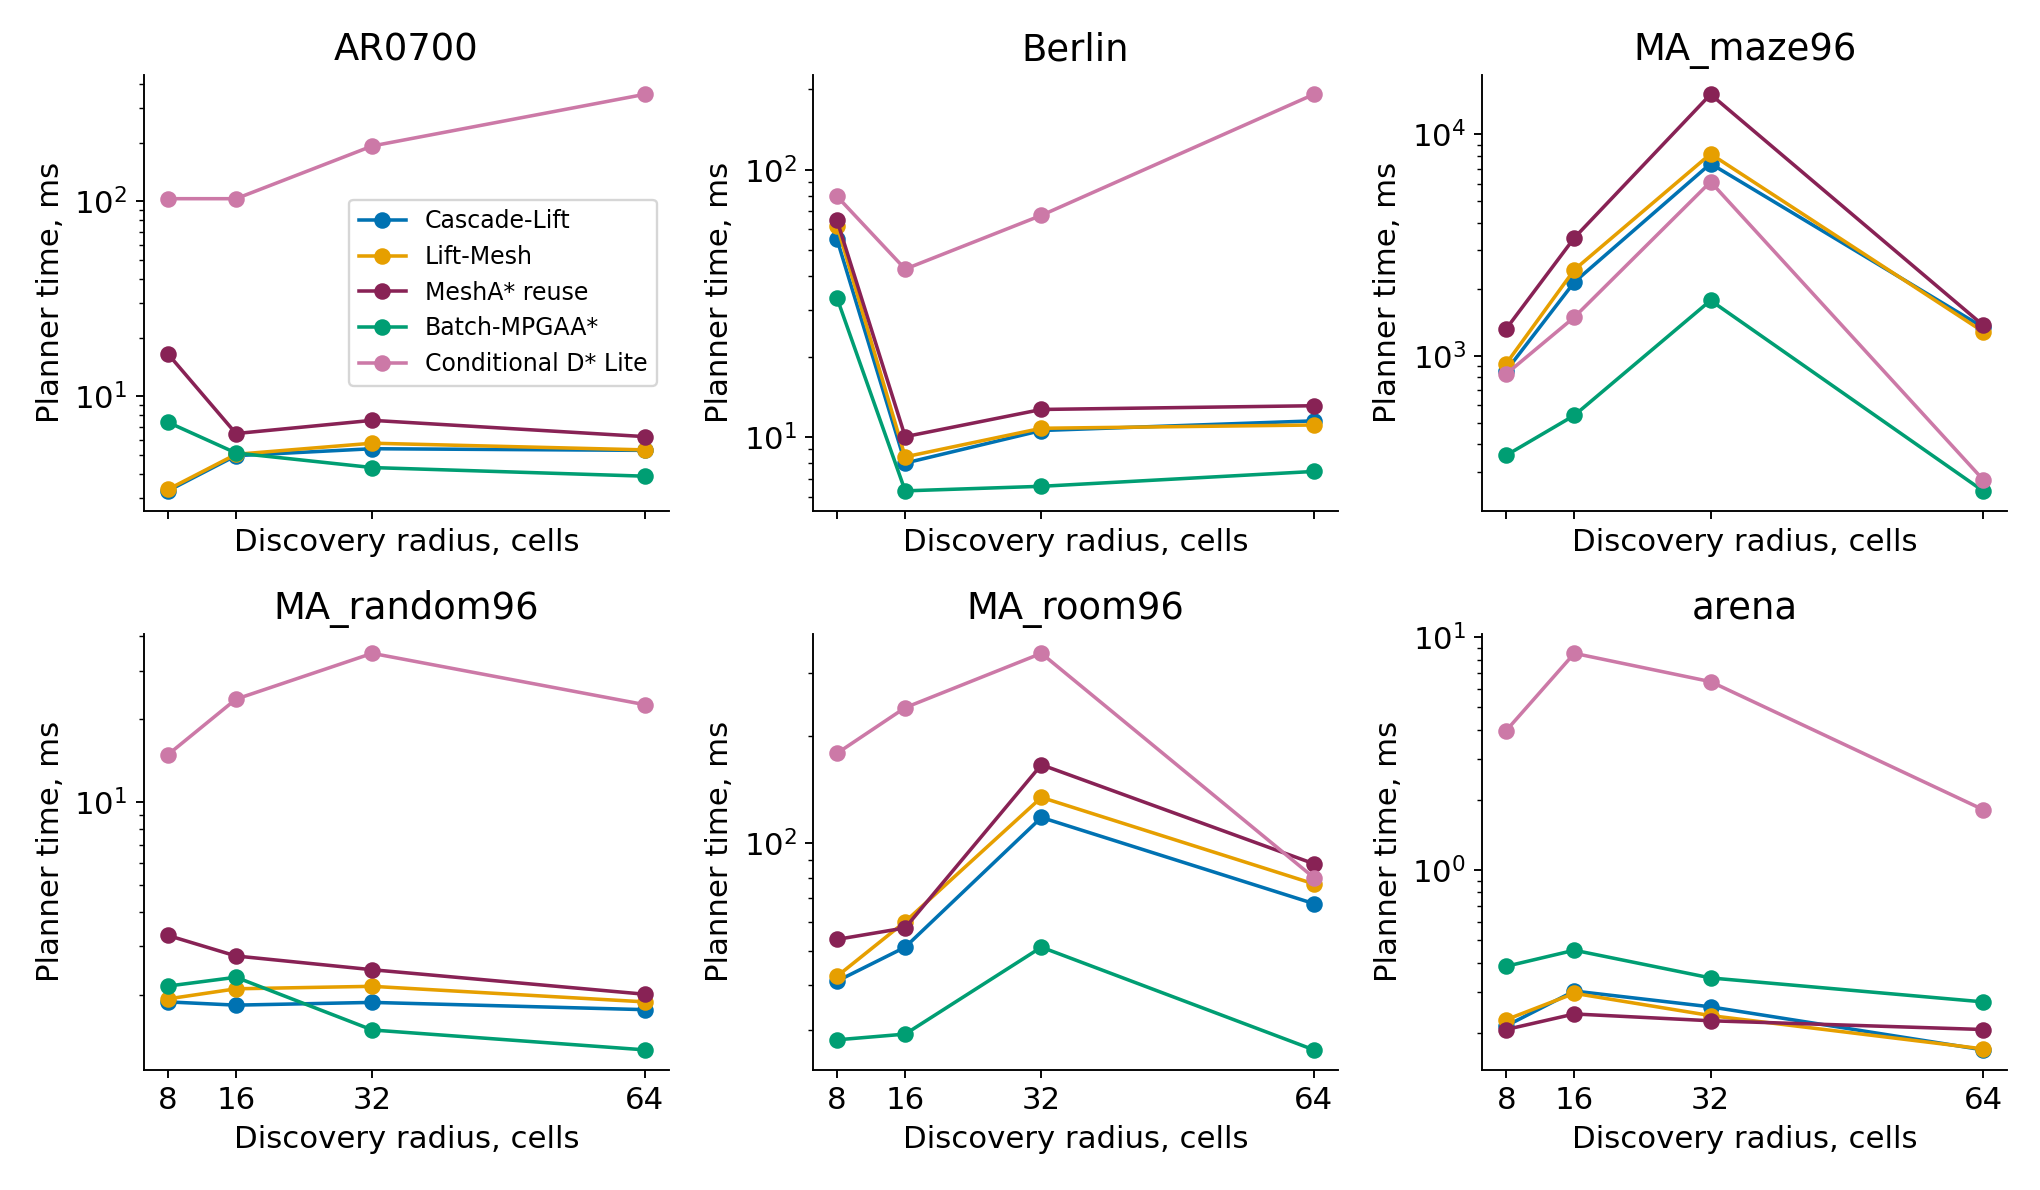

In [3]:
m=pd.read_csv(ad/'map_pairs.csv')
display(m[m.baseline.eq('best_control')])
display(pd.read_csv(ad/'parameter_pairs.csv').query("baseline=='cascade_mesh' and cohort!='replay'"))
display(Image(filename=str(root/'docs/mesh_lift/figures/radius.png')))

,mv_boundary_expansions,mv_interior_expansions,notify_probes,mv_heap_pushes,mv_repair_heap_pushes,mv_repair_local_steps,lift_terminal_prunes,lift_writes
method,,,,,,,,
batch_mpgaa,0,0,96042,0,0,0,0,0
boundary_mesh,0,0,1479760,0,0,0,0,0
cascade_cold,4290067,19698793,0,30175995,0,0,14602478,0
cascade_lift,1883558,12436379,1173,13426390,5169,6443,5517256,7494631
cascade_mesh,820655,13634613,449,8443907,1346,1609,0,0
cmesh_dstar,0,0,2523248,0,0,0,0,0
conditional_dstar,0,0,1423920,0,0,0,0,0
lba_reuse,0,0,0,0,0,0,0,0
lift_cold,4290067,19698793,0,41304372,0,0,14602478,0


,cohort,control,method,configurations,complete
0,navigation_dynamic,car16,batch_mpgaa,36,25
1,navigation_dynamic,car16,cascade_cold,36,25
2,navigation_dynamic,car16,cascade_lift,36,23
3,navigation_dynamic,car16,cascade_mesh,36,17
4,navigation_dynamic,car16,cmesh_dstar,36,25
5,navigation_dynamic,car16,conditional_dstar,36,25
6,navigation_dynamic,car16,lba_reuse,36,24
7,navigation_dynamic,car16,lift_cold,36,25
8,navigation_dynamic,car16,lift_mesh,36,23
9,navigation_dynamic,car16,md_astar,36,25


all_free_calls  online_calls
control method                                         
car16   batch_mpgaa              68388068      55103271
        boundary_mesh            95916163      68858637
        cascade_cold            124068792     111346547
        cascade_lift             68812104      51324575
        cascade_mesh             20022501      10243282
        cmesh_dstar              58606307      23103940
        conditional_dstar        38410540      28617427
        lba_reuse               101981020      90606095
        lift_cold               124068792     111346547
        lift_mesh                68812104      51324575
        lift_noprune             20256665      10344823
        md_astar                 57805696      46430771
        mesha                   124068973     111346696
        mesha_reuse             107037449      94315068
        mpgaa                    57482178      46107357
grid8   batch_mpgaa                844980        564084
        boundary_mesh              849436        446116
        cascade_cold              2213044       1932148
        cascade_lift               875826        538350
        cascade_mesh               743789        462893
        cmesh_dstar               1139263        323899
        conditional_dstar          195474         78942
        lba_reuse                  988002        850554
        lift_cold                 2213044       1932148
        lift_mesh                  875774        538298
        lift_noprune               875826        538350
        md_astar                   227812         90364
        mesha                     2213044       1932148
        mesha_reuse               1914126       1633038
        mpgaa                      227363         90107
        octile_reuse               775054        678454

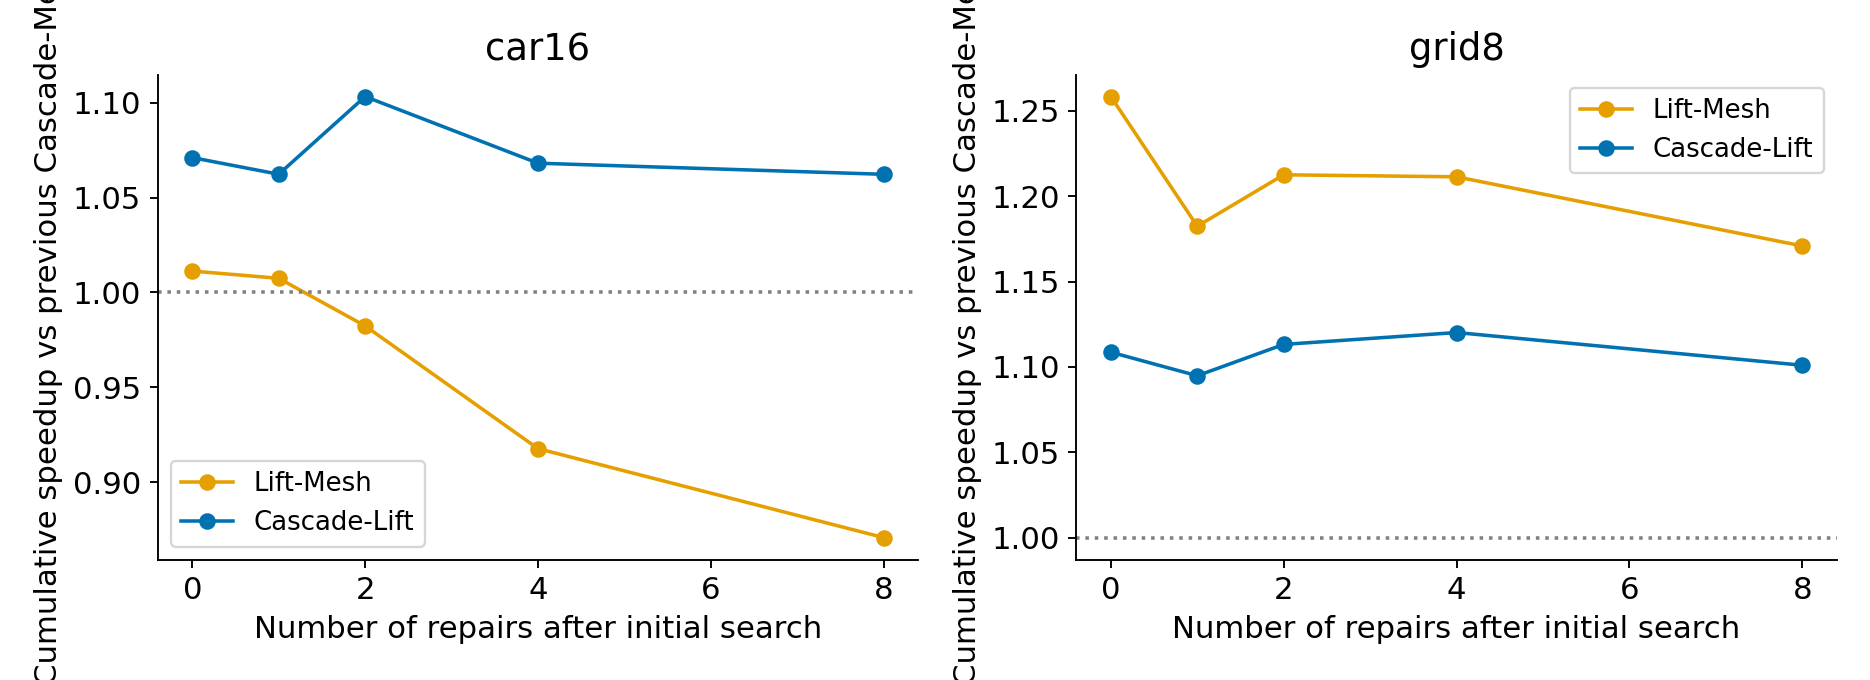

In [4]:
w=pd.read_csv(ad/'work.csv')
display(w.query("cohort=='replay' and control=='car16' and panel=='main'").groupby('method')[['mv_boundary_expansions','mv_interior_expansions','notify_probes','mv_heap_pushes','mv_repair_heap_pushes','mv_repair_local_steps','lift_terminal_prunes','lift_writes']].sum())
display(pd.read_csv(ad/'completion.csv'))
display(pd.read_csv(ad/'collision_probes.csv').groupby(['control','method'])[['all_free_calls','online_calls']].sum())
display(Image(filename=str(root/'docs/mesh_lift/figures/amortization.png')))

Snapshot fields are not additive work; old checked_cells has partial coverage, so the independent all-Grid.free pass supplies common API counts. The contribution hypothesis is compatibility of MeshA terminal pruning and MPGAA learning through local pathmax closure; pathmax and both parent algorithms are known. Per-map losses, caps, clamped rates, trajectories, peak memory and full claim limits are retained in report.pdf and related_work.md.